# 📊 Business Sales Analysis & Performance Dashboard

## Project Overview

This project analyzes historical sales data to understand sales performance, profitability, customer behavior, product performance, and regional trends.

Python is used for data cleaning and exploratory analysis, SQL is used for business analysis, and Power BI is used to build an interactive dashboard for decision-making.

### Tools Used
- Python
- SQL
- Power BI

### Objective
To identify important business trends and insights from sales data and present them through an interactive Power BI dashboard.

## 1. Import Libraries

Import the required Python libraries for data manipulation, analysis, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

Required Python libraries were successfully imported for data analysis and visualization.

## 2. Load Dataset

Load the raw sales dataset into a Pandas DataFrame for analysis.

In [2]:
df = pd.read_csv("../data/raw/Sales_Data_Raw.csv")
df.head()

,transaction_id,sale_date,sale_time,customer_id,product,category,region,sales_channel,payment_method,salesperson,quantity,unit_price,discount_pct,discount_amount,total_sale,cogs,profit
0,TXN000001,2024-08-02,19:10:00,CUST0271,Sunscreen,Beauty,East,Online,Debit Card,SP019,8,1434.78,0,0.00,11478.24,8031.37,3446.87
1,TXN000002,2024-06-09,20:57:00,CUST0344,Cricket Bat,Sports,West,Online,Net Banking,SP021,6,354.41,0,0.00,2126.46,1426.21,700.25
2,TXN000003,2025-04-29,11:06:00,CUST0700,Sneakers,Clothing,East,Store,UPI,SP003,5,2417.35,0,0.00,12086.75,9266.99,2819.76
3,TXN000004,2025-03-30,20:07:00,CUST0777,Wheat Flour,Grocery,South,Store,Cash,SP047,3,1823.17,0,0.00,5469.51,3841.68,1627.83
4,TXN000005,2024-07-20,12:13:00,CUST0772,Jeans,Clothing,Central,Store,Net Banking,SP034,8,2981.09,5,1192.44,22656.28,17469.57,5186.71


## 3. Data Overview

Review the dataset structure, dimensions, columns, and basic information before performing any cleaning.

In [3]:
df.shape

(10000, 17)

In [4]:
df.columns

Index(['transaction_id', 'sale_date', 'sale_time', 'customer_id', 'product',
       'category', 'region', 'sales_channel', 'payment_method', 'salesperson',
       'quantity', 'unit_price', 'discount_pct', 'discount_amount',
       'total_sale', 'cogs', 'profit'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   transaction_id   10000 non-null  object 
 1   sale_date        10000 non-null  object 
 2   sale_time        10000 non-null  object 
 3   customer_id      10000 non-null  object 
 4   product          10000 non-null  object 
 5   category         10000 non-null  object 
 6   region           10000 non-null  object 
 7   sales_channel    10000 non-null  object 
 8   payment_method   10000 non-null  object 
 9   salesperson      10000 non-null  object 
 10  quantity         10000 non-null  int64  
 11  unit_price       10000 non-null  float64
 12  discount_pct     10000 non-null  int64  
 13  discount_amount  10000 non-null  float64
 14  total_sale       10000 non-null  float64
 15  cogs             10000 non-null  float64
 16  profit           10000 non-null  float64
dtypes: float64(5)

In [6]:
df.describe()

,quantity,unit_price,discount_pct,discount_amount,total_sale,cogs,profit
count,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.560900,9876.478941,6.9350,3876.528071,51168.098582,34130.041120,17038.057462
std,2.875607,17142.522623,5.9728,10854.718064,104671.792010,70308.957344,35650.461207
min,1.000000,52.160000,0.0000,0.000000,64.130000,46.610000,15.060000
25%,3.000000,1424.330000,0.0000,0.000000,5448.680000,3579.512500,1778.690000
50%,6.000000,3275.740000,5.0000,568.300000,14334.690000,9495.215000,4716.010000
75%,8.000000,7651.740000,10.0000,2448.147500,39119.880000,25984.250000,13003.130000
max,10.000000,79998.090000,20.0000,137118.480000,799770.000000,616408.660000,311493.840000


## 4. Data Quality Chack

Check for missing values, duplicate record, and invalid data before analysis.

In [7]:
df.isnull().sum()

transaction_id     0
sale_date          0
sale_time          0
customer_id        0
product            0
category           0
region             0
sales_channel      0
payment_method     0
salesperson        0
quantity           0
unit_price         0
discount_pct       0
discount_amount    0
total_sale         0
cogs               0
profit             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,10000.0,5.560900,2.875607,1.00,3.0000,6.000,8.0000,10.00
unit_price,10000.0,9876.478941,17142.522623,52.16,1424.3300,3275.740,7651.7400,79998.09
discount_pct,10000.0,6.935000,5.972800,0.00,0.0000,5.000,10.0000,20.00
discount_amount,10000.0,3876.528071,10854.718064,0.00,0.0000,568.300,2448.1475,137118.48
total_sale,10000.0,51168.098582,104671.792010,64.13,5448.6800,14334.690,39119.8800,799770.00
cogs,10000.0,34130.041120,70308.957344,46.61,3579.5125,9495.215,25984.2500,616408.66
profit,10000.0,17038.057462,35650.461207,15.06,1778.6900,4716.010,13003.1300,311493.84


## 5. Data Cleaning & Validation

Clean and standardize the dataset to make it suitable for analysis.

In [10]:
df[["sale_date", "sale_time"]].head()

,sale_date,sale_time
0,2024-08-02,19:10:00
1,2024-06-09,20:57:00
2,2025-04-29,11:06:00
3,2025-03-30,20:07:00
4,2024-07-20,12:13:00


In [11]:
df[["sale_date", "sale_time"]].dtypes

sale_date    object
sale_time    object
dtype: object

In [12]:
df["sale_date"] = pd.to_datetime(df["sale_date"])
df["sale_date"].dtype

dtype('<M8[ns]')

### Numerical Data Validation

Check the main numerical fields for unexpected negative or zero values.

In [13]:
numerical_column =["quantity", "unit_price", "discount_pct", "discount_amount", "total_sale", "cogs", "profit"]

print("Negative Values")
print((df[numerical_column] < 0 ).sum())
print("\nZero Values")
print((df[numerical_column] == 0 ).sum())

Negative Values
quantity           0
unit_price         0
discount_pct       0
discount_amount    0
total_sale         0
cogs               0
profit             0
dtype: int64

Zero Values
quantity              0
unit_price            0
discount_pct       3014
discount_amount    3014
total_sale            0
cogs                  0
profit                0
dtype: int64


In [14]:
df[numerical_column].describe().T

,count,mean,std,min,25%,50%,75%,max
quantity,10000.0,5.560900,2.875607,1.00,3.0000,6.000,8.0000,10.00
unit_price,10000.0,9876.478941,17142.522623,52.16,1424.3300,3275.740,7651.7400,79998.09
discount_pct,10000.0,6.935000,5.972800,0.00,0.0000,5.000,10.0000,20.00
discount_amount,10000.0,3876.528071,10854.718064,0.00,0.0000,568.300,2448.1475,137118.48
total_sale,10000.0,51168.098582,104671.792010,64.13,5448.6800,14334.690,39119.8800,799770.00
cogs,10000.0,34130.041120,70308.957344,46.61,3579.5125,9495.215,25984.2500,616408.66
profit,10000.0,17038.057462,35650.461207,15.06,1778.6900,4716.010,13003.1300,311493.84


In [15]:
calculated_profit = df["total_sale"] - df["cogs"]

(df["profit"] == calculated_profit).sum()

np.int64(3578)

In [16]:
df["discount_pct"].min(), df["discount_pct"].max()

(0, 20)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   transaction_id   10000 non-null  object        
 1   sale_date        10000 non-null  datetime64[ns]
 2   sale_time        10000 non-null  object        
 3   customer_id      10000 non-null  object        
 4   product          10000 non-null  object        
 5   category         10000 non-null  object        
 6   region           10000 non-null  object        
 7   sales_channel    10000 non-null  object        
 8   payment_method   10000 non-null  object        
 9   salesperson      10000 non-null  object        
 10  quantity         10000 non-null  int64         
 11  unit_price       10000 non-null  float64       
 12  discount_pct     10000 non-null  int64         
 13  discount_amount  10000 non-null  float64       
 14  total_sale       10000 non-null  float6

In [18]:
profit_check = np.isclose(
    df['profit'],
    df['total_sale'] - df['cogs'],
    atol=0.01
)

profit_check.sum()


np.int64(10000)

## 6. Feature Engineering

Create useful business features from the existing sales data to support deeper analysis.

In [19]:
df["year"] = df["sale_date"].dt.year
df["month"] = df["sale_date"].dt.month
df["month_name"] = df["sale_date"].dt.month_name()
df["quarter"] = df["sale_date"].dt.quarter
df["day_name"] = df["sale_date"].dt.day_name()

In [20]:
df[["sale_date", "year", "month", "month_name", "quarter", "day_name"]]

,sale_date,year,month,month_name,quarter,day_name
0,2024-08-02,2024,8,August,3,Friday
1,2024-06-09,2024,6,June,2,Sunday
2,2025-04-29,2025,4,April,2,Tuesday
3,2025-03-30,2025,3,March,1,Sunday
4,2024-07-20,2024,7,July,3,Saturday
...,...,...,...,...,...,...
9995,2025-06-08,2025,6,June,2,Sunday
9996,2024-01-01,2024,1,January,1,Monday
9997,2024-06-21,2024,6,June,2,Friday
9998,2024-10-11,2024,10,October,4,Friday


In [21]:
df["profit_margin"] = ((df["profit"] / df["total_sale"]) * 100).round(2)

In [22]:
df[["total_sale", "profit", "profit_margin"]].head()

,total_sale,profit,profit_margin
0,11478.24,3446.87,30.03
1,2126.46,700.25,32.93
2,12086.75,2819.76,23.33
3,5469.51,1627.83,29.76
4,22656.28,5186.71,22.89


## 7. Exploratory Data Analysis

Explore sales transactions to identify business trends, product performance, and profitability patterns.

### Overall Business Performance

Calculate key business metrics to understand the overall performance of the sales dataset.

In [23]:
total_sale = df["total_sale"].sum()
total_profit = df["profit"].sum()
total_orders = df["transaction_id"].nunique()
total_customers = df['customer_id'].nunique()
total_quantity = df['quantity'].sum()
profit_margin = (total_profit / total_sale) * 100

print(f"Total Sales: {total_sale:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

Total Sales: 511,680,985.82
Total Profit: 170,380,574.62
Total Orders: 10,000
Total Customers: 1,000
Total Quantity Sold: 55,609
Overall Profit Margin: 33.30%


### Monthly Sales Trend

Analyze monthly sales performance to identify growth patterns and seasonal variations.


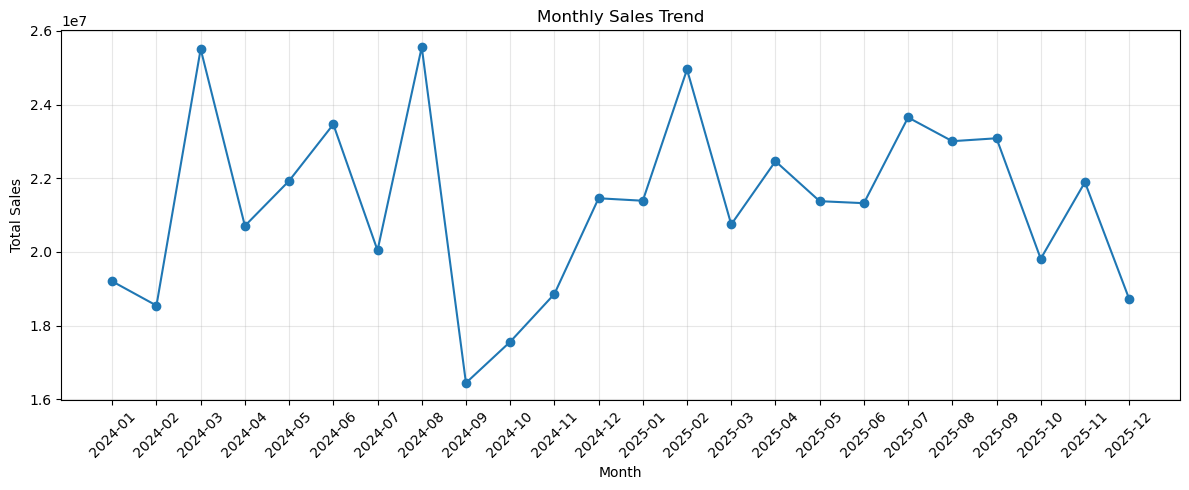

In [24]:
monthly_sales = (
    df.groupby(df['sale_date'].dt.to_period('M'))['total_sale']
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Sales by Category

Compare sales contributions across product categories to identify the strongest revenue-generating categories.


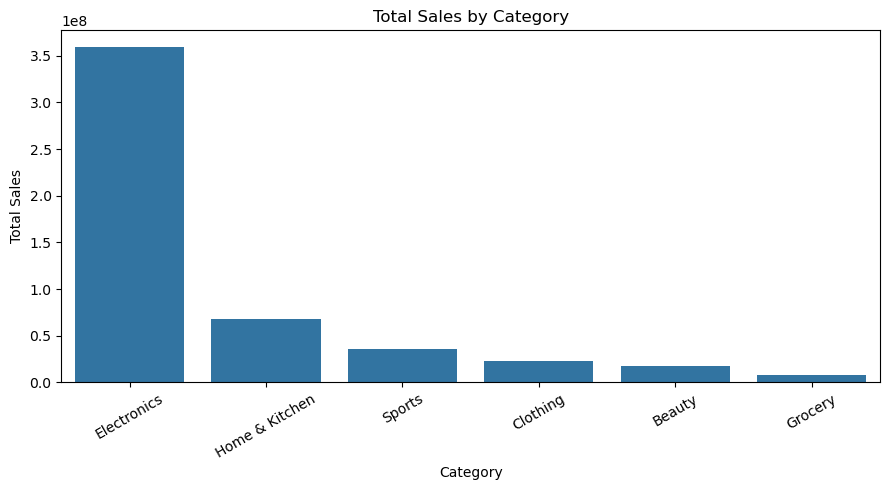

In [25]:
category_sales = (
    df.groupby('category')['total_sale']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Sales by Region

Compare regional sales performance to understand how revenue is distributed across business regions.


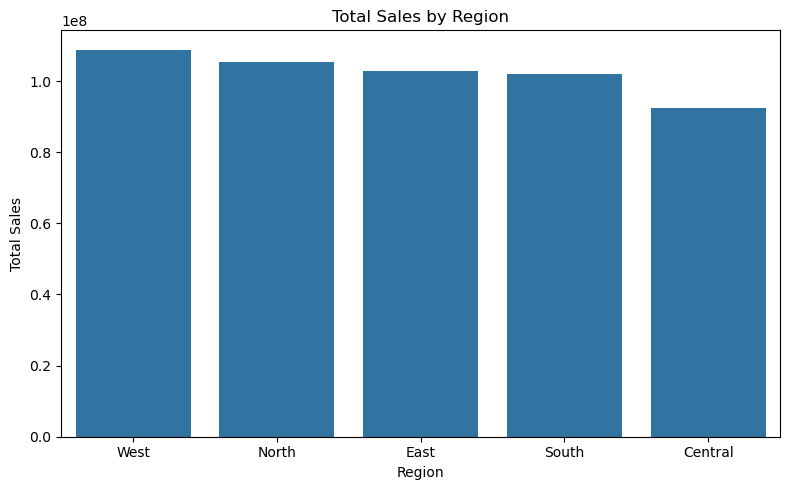

In [26]:
region_sales = (
    df.groupby('region')['total_sale']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

### Profit by Category

Evaluate category-level profitability to identify which product categories contribute most to business profit.


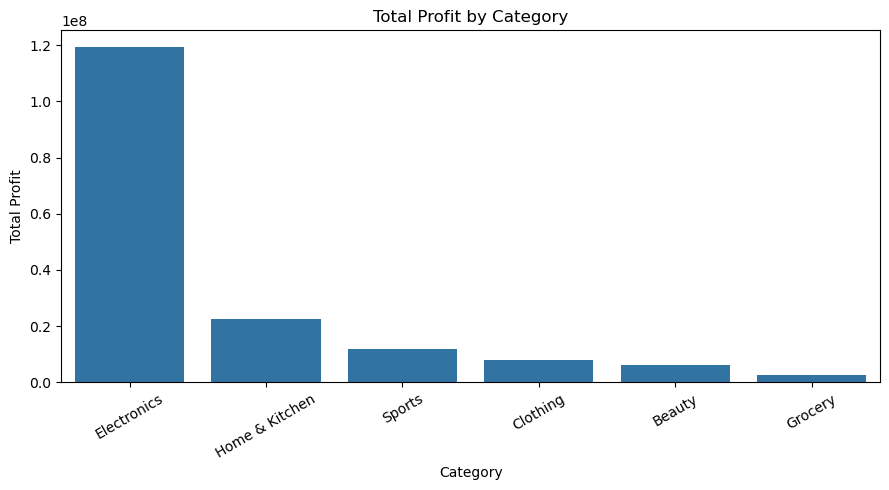

In [27]:
category_profit = (
    df.groupby('category')['profit']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_profit.index, y=category_profit.values)
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Sales Channel Analysis

Compare online and store sales to understand the contribution of each sales channel.


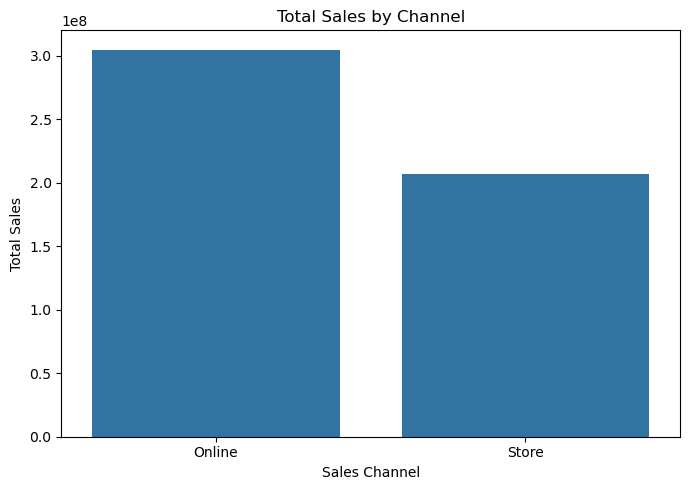

In [28]:
channel_sales = (
    df.groupby('sales_channel')['total_sale']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(x=channel_sales.index, y=channel_sales.values)
plt.title('Total Sales by Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

### Top 10 Products by Sales

Identify the top-performing products based on total sales revenue.


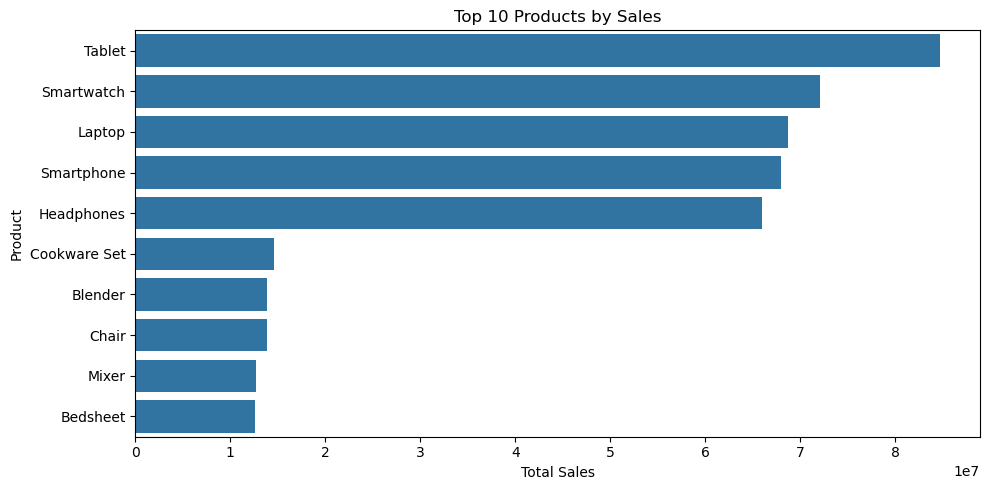

In [29]:
top_products = (
    df.groupby('product')['total_sale']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### Top 10 Customers by Sales

Identify the customers who contribute the highest total sales revenue.


In [30]:
top_customers = (
    df.groupby('customer_id')['total_sale']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

customer_id
CUST0528    2224691.18
CUST0227    2064893.00
CUST0169    1906329.31
CUST0587    1866720.51
CUST0392    1861418.87
CUST0977    1851448.70
CUST0812    1831377.27
CUST0607    1830682.81
CUST0675    1822987.02
CUST0142    1781556.36
Name: total_sale, dtype: float64

## 8. Business Insights

summarize the key findings from the analysis and highlight important business opportunities and performance trends.

In [31]:
print("Highest Sales Category:", category_sales.idxmax())
print("Highest Profit Category:", category_profit.idxmax())
print("Top Sales Region:", region_sales.idxmax())
print("Top Sales Channel:", channel_sales.idxmax())
print("Top-Selling Product:", top_products.index[0])
print("Highest Revenue Customer:", top_customers.index[0])

Highest Sales Category: Electronics
Highest Profit Category: Electronics
Top Sales Region: West
Top Sales Channel: Online
Top-Selling Product: Tablet
Highest Revenue Customer: CUST0528


## 9. Export Clean Dataset

Save the cleaned dataset for SQL analysis and Power BI dashboard development.

In [32]:
df.to_csv("../data/processed/Sales_Data_Cleaned.csv", index=False)

In [33]:
print("Clean dataset exported successfully.")
print("Exported Dataset shape :", df.shape)

Clean dataset exported successfully.
Exported Dataset shape : (10000, 23)


## Conclusion

This notebook prepares and explores the sales dataset, highlights key business performance patterns, and exports a cleaned dataset for the next stages of the project: SQL analysis and the Power BI dashboard.